# Day 2 - Supervised learning practical tasks
***
These tasks cover linear regression, logistic regression, decision trees, model evaluation and regularization.

## Regression models

You will use [Advertising](https://www.kaggle.com/purbar/advertising-data) Dataset. The dataset contains statistics about the sales of a product in 200 different markets, together with advertising budgets in each of these markets for different media channels: TV, radio and newspaper.
#### Your task will be to:
1. Write evaluation functions (MAE, MSE, SSE, RMSE, MAPE, R2).
2. Analyze the correlation matrix.
3. Predict sales values using linear regression.
4. Evaluate model with written statistical explanatory variables.
5. Perform cross-validation (k-fold).
6. Compare your regression model to a reduced model by removing one of the features.
7. Compare your regression model to regularization models.

Please use your code and visualization results made in previous day for data preparation and explanatory analysis.

In [253]:
import pandas as pd
import numpy as np

### 1. Create statistical evaluation functions for regression models

#### 1.1 Create a function that calculates mean absolute error (MAE)

\begin{equation}
MAE = \frac{1}{n} \sum_{i=1}^{n} \left| y_i - \hat{y}_i\right|
\end{equation}

In [254]:
def get_mae(real, guess):
    diff = real - guess
    return np.mean(abs(diff))


#### 1.2 Create a function that calculates mean squared error (MSE)

\begin{equation}
MSE = \frac{1}{n}\cdot SSE
\end{equation}

\begin{equation}
SSE = \sum_{i=1}^n(y_i - \hat{y}_i)^2
\end{equation}

In [255]:
def get_sse(real, guess):
    diff = real - guess
    return np.sum(diff ** 2)

def get_mse(real, guess):
    n = len(real)
    return get_sse(real, guess) / n


#### 1.3 Create a function that calculates root mean squared error (RMSE)

\begin{equation}
RMSE = \sqrt{MSE}
\end{equation}

In [256]:
def get_rmse(real, guess):
    return np.sqrt(get_mse(real, guess))


#### 1.4 Create a function that calculates mean absolute percentage error (MAPE)

\begin{equation}
MAPE = \frac{100}{n} \sum_{i=1}^n \left| \frac{y_i - \hat{y}_i}{y_i} \right|
\end{equation}

In [257]:
def get_mape(real, guess):
    n = len(real)
    diff = real - guess
    return 100 / n * np.sum(abs(diff / real))


#### 1.5 Create a function that calculates coefficient of determination $R^2$ using formula

\begin{equation}
R^2 = \frac{SST-SSE}{SST}
\end{equation}

\begin{equation}
SST = \sum_{i=1}^n (y_i - \bar{y})^2
\end{equation}


In [258]:
def get_r2(real, guess):
    sst = np.sum((real - np.mean(real)) ** 2)
    sse = get_sse(real, guess)
    return (sst - sse) / sst


### 2 Use Linear regression model to make predictions and evaluate it with above developed functions. Perform k-fold cross-validation.

#### 2.1 Read and prepare dataset for modelling - split the data in target variable and features.

In [259]:
ads = pd.read_csv("advertising.csv", index_col=0)
ads.head(10)


,TV,Radio,Newspaper,Sales
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9
6,8.7,48.9,75.0,7.2
7,57.5,32.8,23.5,11.8
8,120.2,19.6,11.6,13.2
9,8.6,2.1,1.0,4.8
10,199.8,2.6,21.2,10.6


In [260]:
ads.info()
ads.isnull().sum()


<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 1 to 200
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

In [261]:
features = ads[["TV", "Radio", "Newspaper"]]
target = ads["Sales"]


#### 2.2. Look at the correlation and visualize the data by methods from day 1 by plots of your choice. Write what you observe.

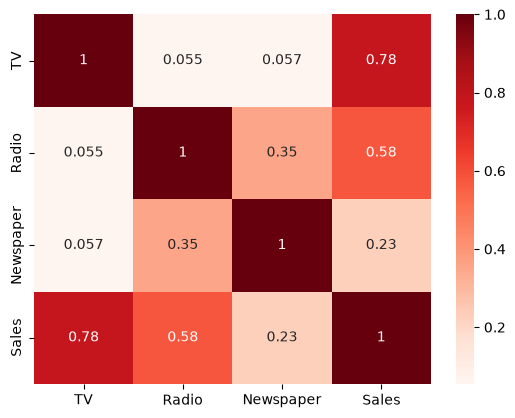

In [262]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(ads.corr(), annot=True, cmap="Reds")
plt.show()



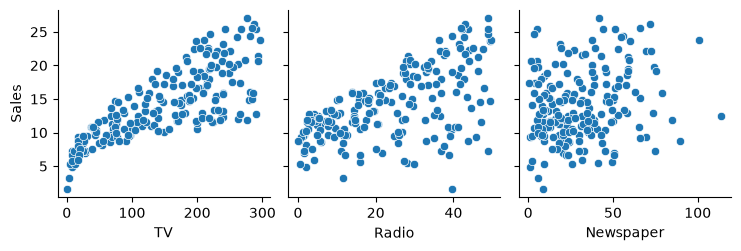

In [263]:
sns.pairplot(ads, x_vars=["TV", "Radio", "Newspaper"], y_vars="Sales")
plt.show()

TV clearly goes together with sales, the more money on TV the more sales. Radio also helps but not that much. Newspaper almost doesnt matter, points are kind of everywhere on the plot. Also no missing values in data so nothing to clean

#### 2.3 Separate the target feature, split data in 2:1 proportion (33% form a holdout set, use random_state=17), and preprocess data with [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html#sklearn.preprocessing.StandardScaler).

In [264]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.33, random_state=17)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


#### 2.4 Fit linear regression model, generate predictions and print regression coefficients $b_0$ and $b_1$.

In [265]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 3.97, 2.88,-0.07]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,14.02
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](3,)","[13.67,11.09, 9.6 ]"


In [266]:
sales_guess = model.predict(X_test)
print("b0:", model.intercept_)
print("b1, b2, b3:", model.coef_)


b0: 14.022388059701495
b1, b2, b3: [ 3.9675339   2.88155345 -0.07344038]


#### 2.5 Evaluate created model with above functions

In [267]:
print("MAE: ", get_mae(y_test, sales_guess))
print("MSE: ", get_mse(y_test, sales_guess))
print("RMSE:", get_rmse(y_test, sales_guess))
print("MAPE:", get_mape(y_test, sales_guess))
print("R2:  ", get_r2(y_test, sales_guess))


MAE:  1.241490259650847
MSE:  3.47262996875279
RMSE: 1.8634993879131783
MAPE: 18.638804594568974
R2:   0.8515370160992793


#### 2.6 Perform k-fold cross-validation $(k=10)$ and print the mean $R^2$ score to get an overall performance metric.

Please use [cross_val_score](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
with [r2](https://scikit-learn.org/stable/modules/model_evaluation.html#the-scoring-parameter-defining-model-evaluation-rules) score.

In [268]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(LinearRegression(), X_train, y_train, cv=10, scoring="r2")
print("Mean R2:", scores.mean())


Mean R2: 0.8982698791408206


#### 2.7. Drop one of the three variables (TV, Radio or Newspaper) and create another model, evaluate it and compare to the first model.

In [269]:
small_features = ads[["TV", "Radio"]]

X_tr2, X_te2, y_tr2, y_te2 = train_test_split(small_features, target, test_size=0.33, random_state=17)

scaler2 = StandardScaler()
X_tr2 = scaler2.fit_transform(X_tr2)
X_te2 = scaler2.transform(X_te2)

model2 = LinearRegression()
model2.fit(X_tr2, y_tr2)
guess2 = model2.predict(X_te2)


In [270]:
print("Full model (TV, Radio, Newspaper)")
print("  MSE:", get_mse(y_test, sales_guess))
print("  R2: ", get_r2(y_test, sales_guess))

print("Small model (TV, Radio)")
print("  MSE:", get_mse(y_te2, guess2))
print("  R2: ", get_r2(y_te2, guess2))


Full model (TV, Radio, Newspaper)
  MSE: 3.47262996875279
  R2:  0.8515370160992793
Small model (TV, Radio)
  MSE: 3.458740998763223
  R2:  0.8521308017736854


I dropped newspaper because its correlation was the lowest. Results are pretty much same, even a tiny bit better, so newspaper doesnt really help to predict sales

### 3. Use regularization models with regularization strength `alpha=1` and compare $MSE$ values with previous models.

#### 3.1 Lasso regression

In [271]:
from sklearn.linear_model import Lasso

lasso = Lasso(alpha=1)
lasso.fit(X_train, y_train)
lasso_guess = lasso.predict(X_test)

print("Lasso MSE:", get_mse(y_test, lasso_guess))
print("Coefficients:", lasso.coef_)


Lasso MSE: 4.911579294712751
Coefficients: [3.0619592  1.96202634 0.        ]


#### 3.2 Ridge regression

In [272]:
from sklearn.linear_model import Ridge

ridge = Ridge(alpha=1)
ridge.fit(X_train, y_train)
ridge_guess = ridge.predict(X_test)

print("Ridge MSE:", get_mse(y_test, ridge_guess))
print("Coefficients:", ridge.coef_)


Ridge MSE: 3.4768894774722394
Coefficients: [ 3.93899368  2.85996406 -0.06218255]


#### 3.3 Elastic net regression

Use any `l1_ratio` of your choice.


In [273]:
from sklearn.linear_model import ElasticNet

enet = ElasticNet(alpha=1, l1_ratio=0.4)
enet.fit(X_train, y_train)
enet_guess = enet.predict(X_test)

print("ElasticNet MSE:", get_mse(y_test, enet_guess))
print("Coefficients:", enet.coef_)


ElasticNet MSE: 7.143519772276349
Coefficients: [2.30344631 1.63694628 0.09468248]


#### 3.4 Make conclusions

In [274]:
print("Linear (all 3): ", get_mse(y_test, sales_guess))
print("Linear (TV+Radio):", get_mse(y_te2, guess2))
print("Lasso:          ", get_mse(y_test, lasso_guess))
print("Ridge:          ", get_mse(y_test, ridge_guess))
print("ElasticNet:     ", get_mse(y_test, enet_guess))


Linear (all 3):  3.47262996875279
Linear (TV+Radio): 3.458740998763223
Lasso:           4.911579294712751
Ridge:           3.4768894774722394
ElasticNet:      7.143519772276349


Ridge gave almost same result as normal linear regression. Lasso put newspaper to 0 but overall error got bigger, and elastic net was the worst one, I think alpha 1 is too strong for this data. Best model was simple linear regression with only TV and radio. We have just 3 features so there is not much overfitting and regularization doesnt really help here

## Classification models

You will use [Diabetes](https://www.kaggle.com/uciml/pima-indians-diabetes-database) dataset. The dataset includes data from 768 women with several medical predictor variables and one target variable. The classification goal is to predict whether or not the patients in the dataset have diabetes.
#### Your task will be to:
1. Write evaluation functions (Accuracy, Precision, Recall, F1).
2. Predict whether or not a patient has diabetes using Logistic regression and Decision Tree Classification models
3. Evaluate both models with written statistical explanatory variables
4. Draw ROC curve and compute AUC
5. Perform cross-validation (k-fold)
6. Analyze the results

Please use your code and visualization results made in previous day for data preparation and explanatory analysis.

### 1. Write statistical evaluation functions for classification models

#### 1.1 Create a function that calculates accuracy

\begin{equation}
Accuracy = \frac{True Positive + True Negative}{True Positive + True Negative + False Positive + False Negative}
\end{equation}

In [275]:
def count_results(real, guess):
    real = list(real)
    guess = list(guess)
    tp = tn = fp = fn = 0
    for r, g in zip(real, guess):
        if r == 1 and g == 1:
            tp += 1
        elif r == 0 and g == 0:
            tn += 1
        elif r == 0 and g == 1:
            fp += 1
        else:
            fn += 1
    return tp, tn, fp, fn

def get_accuracy(real, guess):
    tp, tn, fp, fn = count_results(real, guess)
    return (tp + tn) / (tp + tn + fp + fn)


#### 1.2 Create a function that calculates precision

\begin{equation}
Precision = \frac{True Positive}{True Positive + False Positive}
\end{equation}

In [276]:
def get_precision(real, guess):
    tp, tn, fp, fn = count_results(real, guess)
    if tp + fp == 0:
        return 0
    return tp / (tp + fp)

#### 1.3  Create a function that calculates recall

\begin{equation}
Recall = \frac{True Positive}{True Positive + False Negative}
\end{equation}

In [277]:
def get_recall(real, guess):
    tp, tn, fp, fn = count_results(real, guess)
    if tp + fn == 0:
        return 0
    return tp / (tp + fn)

#### 1.4 Create a function that calculates $F1$ - score

\begin{equation}
F1 = 2\cdot \frac{Precision \cdot Recall}{Precision + Recall}
\end{equation}

In [278]:
def get_f1(real, guess):
    p = get_precision(real, guess)
    r = get_recall(real, guess)
    if p + r == 0:
        return 0
    return 2 * p * r / (p + r)

### 2. Use logistic regression to make prediction and evaluate it with above developed functions. Compute ROC and compute AUC. Perform k-fold cross-validation.

#### 2.1 Read and prepare dataset for modelling. Split the data in target variable and features.

Prepare dataset to use it for modelling (you should also replace 0 values in columns `Glucose`, `BloodPressure`,`SkinThickness`,`Insulin`,`BMI` with mean values).

In [279]:
sugar = pd.read_csv("diabetes.csv")

# 0 in these columns means missing (nobody has 0 blood pressure lol)
zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
for col in zero_cols:
    sugar[col] = sugar[col].replace(0, np.nan)
    sugar[col] = sugar[col].fillna(sugar[col].mean())

X = sugar.drop("Outcome", axis=1)
y = sugar["Outcome"]

# check that zeros are gone
print((sugar[zero_cols] == 0).sum())
sugar.head()

Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.00000,155.548223,33.6,0.627,50,1
1,1,85.0,66.0,29.00000,155.548223,26.6,0.351,31,0
2,8,183.0,64.0,29.15342,155.548223,23.3,0.672,32,1
3,1,89.0,66.0,23.00000,94.000000,28.1,0.167,21,0
4,0,137.0,40.0,35.00000,168.000000,43.1,2.288,33,1


#### 2.2. Look at the correlation and visualize the data by methods from day 1 by plots of your choice. Write what you observe.

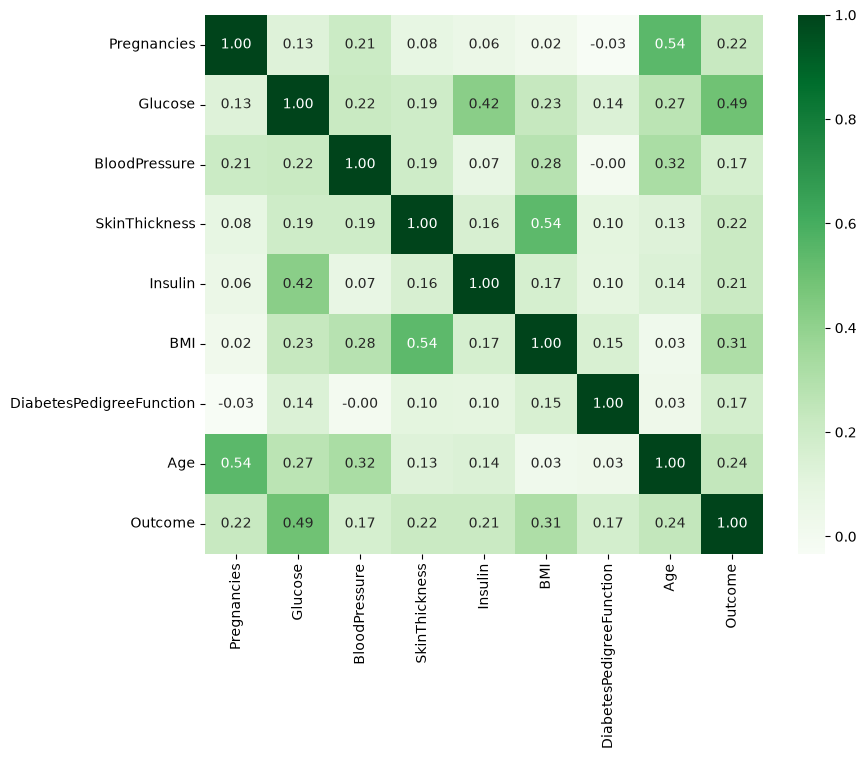

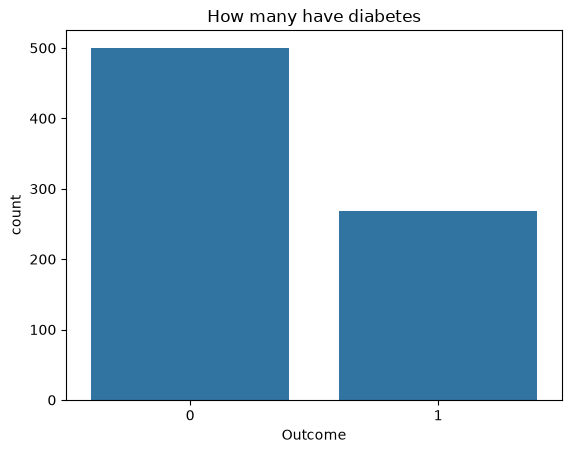

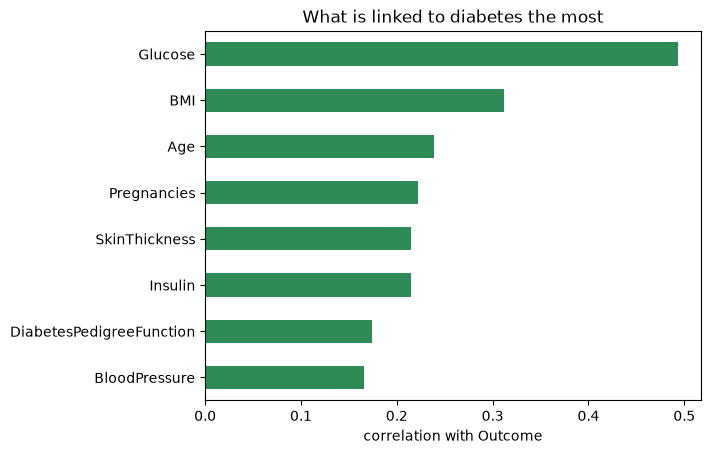

In [280]:
plt.figure(figsize=(9, 7))
sns.heatmap(sugar.corr(), annot=True, fmt=".2f", cmap="Greens")
plt.show()

sns.countplot(x="Outcome", data=sugar)
plt.title("How many have diabetes")
plt.show()

links = sugar.corr()["Outcome"].drop("Outcome").sort_values()
links.plot(kind="barh", color="seagreen")
plt.title("What is linked to diabetes the most")
plt.xlabel("correlation with Outcome")
plt.show()

Glucose is clearly the top one, around 0.49 correlation with outcome. BMI is next with about 0.31, then age and pregnancies but they are much weaker. Blood pressure barely matters. Also there are way more people without diabetes, 500 vs 268, so data is not balanced and I should keep it in mind when looking at accuracy

#### 2.3 Separate the target feature, split data in 2:1 proportion (33% form a holdout set, use random_state=17), and preprocess data with [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)

In [281]:
train_X, test_X, train_y, test_y = train_test_split(X, y, test_size=0.33, random_state=17)

scaler_d = StandardScaler()
train_X = scaler_d.fit_transform(train_X)
test_X = scaler_d.transform(test_X)

print("train:", train_X.shape, " test:", test_X.shape)

train: (514, 8)  test: (254, 8)


#### 2.4 Fit logistic regression model, generate predictions

In [282]:
from sklearn.linear_model import LogisticRegression

# balanced because there are way more 0 than 1 in outcome
logreg = LogisticRegression(class_weight="balanced")
logreg.fit(train_X, train_y)
log_guess = logreg.predict(test_X)

print(log_guess[:10])

[0 1 0 0 0 1 0 1 1 1]


#### 2.5 Create a confusion matrix and evaluate created model with above functions

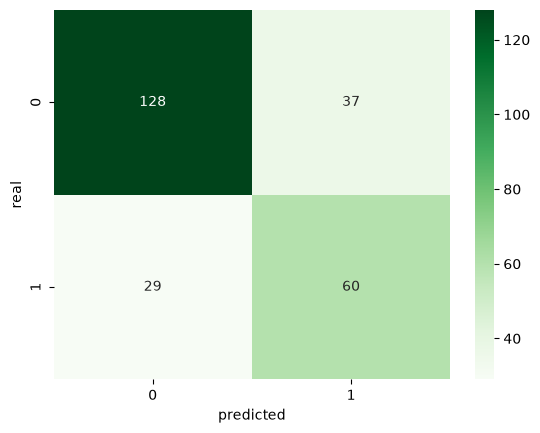

Accuracy: 0.7401574803149606
Precision: 0.6185567010309279
Recall: 0.6741573033707865
F1: 0.6451612903225807


In [283]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(test_y, log_guess)
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens")
plt.xlabel("predicted")
plt.ylabel("real")
plt.show()

print("Accuracy:", get_accuracy(test_y, log_guess))
print("Precision:", get_precision(test_y, log_guess))
print("Recall:", get_recall(test_y, log_guess))  # without balanced it was only 0.52
print("F1:", get_f1(test_y, log_guess))

#### 2.6 Draw a ROC curve and compute Area Under the Curve (AUC)

You can use [roc_auc_score](http://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html) and [RocCurveDisplay.from_predictions](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.RocCurveDisplay.html#sklearn.metrics.RocCurveDisplay.from_predictions).
Check documentation for examples.
For roc_auc_score use predicted probabilities (`predict_proba`), not predicted values. This will align your AUC and ROC curve values.

`predict_proba()` method returns a two-dimensional array. For each instance the predicted class is the class with the maximum probability. To calculate AUC correctly, you need the probability of the positive class (second column, `[:, 1]`).

AUC: 0.8303030303030303


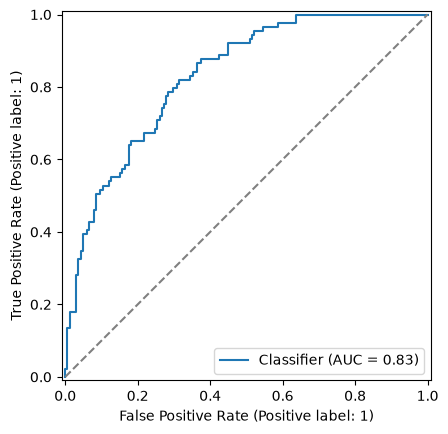

In [284]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay

# need probability of class 1, not 0/1 predictions
log_proba = logreg.predict_proba(test_X)[:, 1]
print("AUC:", roc_auc_score(test_y, log_proba))

RocCurveDisplay.from_predictions(test_y, log_proba)
plt.plot([0, 1], [0, 1], "--", color="gray")  # random guess line
plt.show()

#### 2.7 Perform k-fold cross-validation $(k=10)$ and print the mean accuracy to get an overall performance metric.

Use [cross_val_score](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
with [accuracy](https://scikit-learn.org/stable/modules/model_evaluation.html#the-scoring-parameter-defining-model-evaluation-rules). Feed your scaled X train and y train data.

In [285]:
log_scores = cross_val_score(LogisticRegression(class_weight="balanced"), train_X, train_y, cv=10, scoring="accuracy")
print("Mean accuracy:", log_scores.mean())

Mean accuracy: 0.7549396681749623


### 3. Use Decision tree classification model to make predictions and evaluate it with above developed functions. Draw ROC curve and compute AUC. Perform k-fold cross-validation.

#### 3.1 Create classification tree object, fit model and generate predictions

In [286]:
from sklearn.tree import DecisionTreeClassifier

# without max_depth the tree overfits, min_samples_leaf so it doesnt make tiny leaves
tree = DecisionTreeClassifier(max_depth=5, min_samples_leaf=10, random_state=17)
tree.fit(train_X, train_y)
tree_guess = tree.predict(test_X)

print(tree_guess[:10])

[0 1 0 0 1 1 0 1 1 0]


#### 3.2 Evaluate created model with above functions

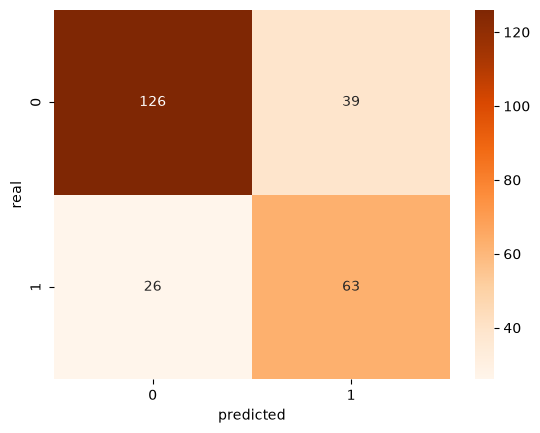

Accuracy: 0.7440944881889764
Precision: 0.6176470588235294
Recall: 0.7078651685393258
F1: 0.6596858638743456


In [287]:
cm_tree = confusion_matrix(test_y, tree_guess)
sns.heatmap(cm_tree, annot=True, fmt="d", cmap="Oranges")
plt.xlabel("predicted")
plt.ylabel("real")
plt.show()

print("Accuracy:", get_accuracy(test_y, tree_guess))
print("Precision:", get_precision(test_y, tree_guess))
print("Recall:", get_recall(test_y, tree_guess))
print("F1:", get_f1(test_y, tree_guess))

#### 3.3 Draw a ROC curve and compute Area Under the Curve (AUC)

AUC: 0.8072863466121893


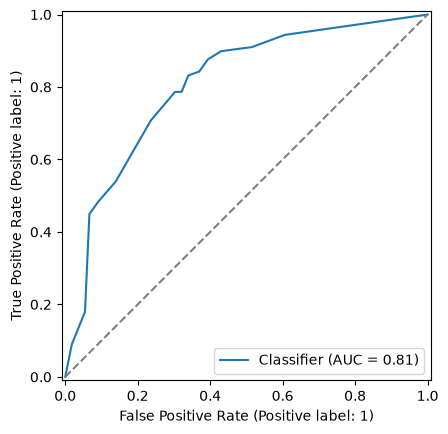

In [288]:
tree_proba = tree.predict_proba(test_X)[:, 1]
print("AUC:", roc_auc_score(test_y, tree_proba))

RocCurveDisplay.from_predictions(test_y, tree_proba)
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.show()

#### 3.4 Perform k-fold cross-validation $(k=10)$ and print the mean accuracy to get an overall performance metric.

In [289]:
tree_scores = cross_val_score(DecisionTreeClassifier(max_depth=5, min_samples_leaf=10, random_state=17), train_X, train_y, cv=10, scoring="accuracy")
print("Mean accuracy:", tree_scores.mean())

Mean accuracy: 0.7784690799396682


#### 3.5 Make conclusions

Both models ended up pretty close, accuracy around 0.74 for both. I used class_weight balanced for logistic regression because data has much more healthy people, and recall went from 0.52 to 0.67 so it misses less diabetes cases. The tree has a bit better recall (0.71) and F1 (0.66 vs 0.65), and the best cross validation score 0.78 vs 0.76, so it looks more stable after I added min_samples_leaf. Logistic regression still has better AUC (0.83 vs 0.81). Overall I would pick the tree because for diabetes its more important to find sick people, but honestly the difference is small. Accuracy alone is not very useful here because data is not balanced